# T03 — Spatial derivative machinery manual check

Scope (per `tasks.md` T03 and the 2026-09-22 task instructions):

- `iste.derivatives.spatial_gradient` — the generic gradient operator for any scalar
  gridded field (does **not** choose a value/formula for `K`);
- `iste.derivatives.divergence_2d` — divergence of a 2-D vector field, used here with
  the T01.5-locked `U = (uo, vo)` (windage excluded);
- `iste.geometry` — the explicit, documented spherical-Earth degree-to-metre conversion
  both operators use (never treating a degree as a constant distance).

No particle propagation, Euler-Maruyama, particle weights, boundary/trajectory logic,
forcing ensemble, KDE, likelihood, SMC, MCMC, or AIS is implemented or exercised here.

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt

from iste.derivatives import divergence_2d, spatial_gradient
from iste.environment import load_field_dataset
from iste.geometry import metres_per_degree_latitude, metres_per_degree_longitude

OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")

LAT = np.linspace(10.0, 30.0, 9)   # ascending, uniform 2.5-degree spacing
LON = np.linspace(100.0, 120.0, 11)  # ascending, uniform 2.0-degree spacing

## 1. Units of the returned quantities

`spatial_gradient(lat, lon, field)` returns `(d_dx, d_dy, valid)` where `x` is eastward
physical distance and `y` is northward physical distance, both in **metres** (spherical
Earth approximation, `iste.geometry`). So `d_dx`/`d_dy` are in `[field units] / metre`.
`divergence_2d(lat, lon, u, v)` returns `div(U)` in `[u/v units] / metre` — `1/s` when
`u`/`v` are m/s (as `uo`/`vo` are).

## 2. Known constant gradient (analytically checkable)

`field[i, j] = lat[i]` (independent of longitude). Analytically:
`d(field)/dx = 0` and `d(field)/dy = 1 / metres_per_degree_latitude()` — a single
constant, everywhere, including at the grid edges.

In [2]:
field_const_grad = np.broadcast_to(LAT[:, None], (len(LAT), len(LON))).astype(np.float64)
d_dx, d_dy, valid = spatial_gradient(LAT, LON, field_const_grad)
expected_d_dy = 1.0 / metres_per_degree_latitude()
print(f"d_dx: expected 0 everywhere, max|actual| = {np.abs(d_dx).max():.3e}")
print(f"d_dy: expected {expected_d_dy:.6e} everywhere, actual range = [{d_dy.min():.6e}, {d_dy.max():.6e}]")
print(f"valid everywhere: {bool(np.all(valid))}")

d_dx: expected 0 everywhere, max|actual| = 0.000e+00
d_dy: expected 8.993216e-06 everywhere, actual range = [8.993216e-06, 8.993216e-06]
valid everywhere: True


## 3. Spatially varying gradient (analytically checkable, including edges)

`field[i, j] = lon[j]**2` (independent of latitude). Analytically
`d(field)/d(lon_deg) = 2*lon[j]` exactly (central *and* the `edge_order=2` boundary
formula are both exact for a quadratic), so
`d(field)/dx = 2*lon[j] / metres_per_degree_longitude(lat[i])` — varying with both
longitude and latitude. `d(field)/dy = 0` everywhere.

max |computed - analytic| over the whole grid (interior + edges): 0.000e+00
d_dy: expected 0 everywhere, max|actual| = 1.636e-17


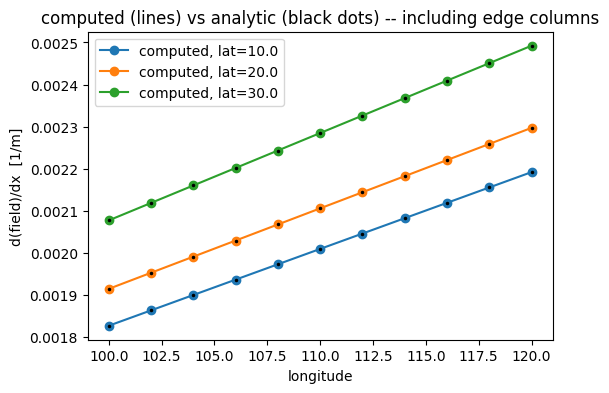

In [3]:
field_varying = np.broadcast_to(LON[None, :] ** 2, (len(LAT), len(LON))).astype(np.float64)
d_dx2, d_dy2, valid2 = spatial_gradient(LAT, LON, field_varying)
dlon_per_deg = metres_per_degree_longitude(LAT)
expected_d_dx2 = (2.0 * LON[None, :]) / dlon_per_deg[:, None]

max_err = np.abs(d_dx2 - expected_d_dx2).max()
print(f"max |computed - analytic| over the whole grid (interior + edges): {max_err:.3e}")
print(f"d_dy: expected 0 everywhere, max|actual| = {np.abs(d_dy2).max():.3e}")

fig, ax = plt.subplots(figsize=(6, 4))
for i in (0, len(LAT) // 2, -1):
    ax.plot(LON, d_dx2[i], "o-", label=f"computed, lat={LAT[i]:.1f}")
    ax.plot(LON, expected_d_dx2[i], "k.", markersize=3)
ax.set_xlabel("longitude"); ax.set_ylabel("d(field)/dx  [1/m]")
ax.set_title("computed (lines) vs analytic (black dots) -- including edge columns")
ax.legend()
plt.show()

## 4. Ascending vs. descending latitude give the same physical answer

In [4]:
lat_desc = LAT[::-1]
field_desc = field_const_grad[::-1, :]
d_dx3, d_dy3, valid3 = spatial_gradient(lat_desc, LON, field_desc)
print(f"descending-latitude grid: d_dx max|.|={np.abs(d_dx3).max():.3e} (expect ~0), "
      f"d_dy in [{d_dy3.min():.6e}, {d_dy3.max():.6e}] (expect {expected_d_dy:.6e})")

descending-latitude grid: d_dx max|.|=0.000e+00 (expect ~0), d_dy in [8.993216e-06, 8.993216e-06] (expect 8.993216e-06)


## 5. Invalid/NaN-cell behaviour

A single masked cell must invalidate itself and its immediate finite-difference
neighbours in each direction -- and nothing farther away.

In [5]:
field_gap = field_const_grad.copy()
i0, j0 = 4, 5
field_gap[i0, j0] = np.nan
_, _, valid_gap = spatial_gradient(LAT, LON, field_gap)

print("validity around the masked cell (row i0-2..i0+2, col j0-2..j0+2):")
print(valid_gap[i0 - 2 : i0 + 3, j0 - 2 : j0 + 3].astype(int))
print("(1 = valid, 0 = invalid; the 0s should form a small '+' centred on the masked cell)")

validity around the masked cell (row i0-2..i0+2, col j0-2..j0+2):
[[1 1 1 1 1]
 [1 1 0 1 1]
 [1 0 0 0 1]
 [1 1 0 1 1]
 [1 1 1 1 1]]
(1 = valid, 0 = invalid; the 0s should form a small '+' centred on the masked cell)


## 6. Known divergence (analytically checkable)

`u` = physical eastward position (m), `v` = physical northward position (m) -- both
linear in physical space, so `du/dx = dv/dy = 1` exactly and `div(U) = 2` everywhere.
A second, unrelated field gives an *exactly* zero-divergence case.

In [6]:
dlat_per_deg = metres_per_degree_latitude()
u_known = LON[None, :] * dlon_per_deg[:, None]
v_known = np.broadcast_to((LAT * dlat_per_deg)[:, None], (len(LAT), len(LON))).astype(np.float64)
div_known, valid_known = divergence_2d(LAT, LON, u_known, v_known)
print(f"known divergence: expected 2.0 everywhere, actual range = [{div_known.min():.8f}, {div_known.max():.8f}]")

u_zero = np.broadcast_to(np.sin(np.deg2rad(LAT))[:, None], (len(LAT), len(LON))).astype(np.float64)
v_zero = np.broadcast_to((LON**3)[None, :], (len(LAT), len(LON))).astype(np.float64)
div_zero, _ = divergence_2d(LAT, LON, u_zero, v_zero)
print(f"zero-divergence field: expected 0.0 everywhere, max|actual| = {np.abs(div_zero).max():.3e}")

known divergence: expected 2.0 everywhere, actual range = [2.00000000, 2.00000000]
zero-divergence field: expected 0.0 everywhere, max|actual| = 1.570e-15


## 7. Real data: `div(U)` on the ocean grid (sanity check only, not scientific validation)

This confirms the implementation is numerically self-consistent on real data -- it is
**not** a claim that the resulting divergence field has been physically/scientifically
validated.

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

valid fraction at t=100: 0.706
div(U) range over valid cells: [-4.919e-05, 3.328e-05] 1/s


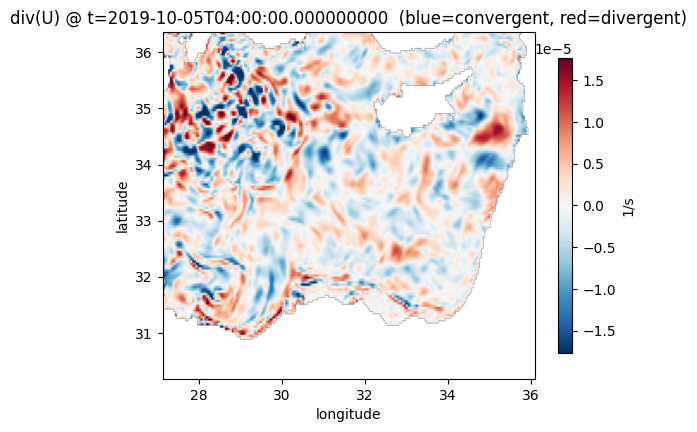

In [7]:
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")
t_plot = 100
div_real, valid_real = divergence_2d(ocean.lat, ocean.lon, ocean.data["uo"][t_plot], ocean.data["vo"][t_plot])
print(f"valid fraction at t={t_plot}: {valid_real.mean():.3f}")
print(f"div(U) range over valid cells: [{np.nanmin(div_real):.3e}, {np.nanmax(div_real):.3e}] 1/s")

extent = [ocean.lon.min(), ocean.lon.max(), ocean.lat.min(), ocean.lat.max()]
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(div_real, origin="lower", extent=extent, aspect="auto", cmap="RdBu_r",
                vmin=-np.nanpercentile(np.abs(div_real), 99), vmax=np.nanpercentile(np.abs(div_real), 99))
ax.set_title(f"div(U) @ t={ocean.time[t_plot]}  (blue=convergent, red=divergent)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig.colorbar(im, ax=ax, shrink=0.85, label="1/s")
plt.show()

In [8]:
# Independent hand-computed check at one real, fully-valid interior '+' neighbourhood.
uo = ocean.data["uo"]
vo = ocean.data["vo"]
t_idx = i0 = j0 = None
for t in range(uo.shape[0]):
    u_finite = ~np.isnan(uo[t])
    v_finite = ~np.isnan(vo[t])
    u_ok = u_finite[1:-1, :-2] & u_finite[1:-1, 1:-1] & u_finite[1:-1, 2:]
    v_ok = v_finite[:-2, 1:-1] & v_finite[1:-1, 1:-1] & v_finite[2:, 1:-1]
    hits = np.argwhere(u_ok & v_ok)
    if hits.size:
        t_idx = t
        i0, j0 = hits[0] + 1
        break

lat, lon = ocean.lat, ocean.lon
dlon_per_deg_i0 = metres_per_degree_longitude(lat[i0])
du_dlon = (uo[t_idx, i0, j0 + 1] - uo[t_idx, i0, j0 - 1]) / (lon[j0 + 1] - lon[j0 - 1])
dv_dlat = (vo[t_idx, i0 + 1, j0] - vo[t_idx, i0 - 1, j0]) / (lat[i0 + 1] - lat[i0 - 1])
expected_div = (du_dlon / dlon_per_deg_i0) + (dv_dlat / dlat_per_deg)

div_field, valid_field = divergence_2d(lat, lon, uo[t_idx], vo[t_idx])
print(f"hand-computed div(U) at ({lat[i0]:.3f}, {lon[j0]:.3f}), t={ocean.time[t_idx]}: {expected_div:.8e}")
print(f"divergence_2d output at the same point:                                  {div_field[i0, j0]:.8e}")
print(f"valid: {bool(valid_field[i0, j0])}")

hand-computed div(U) at (30.896, 29.000), t=2019-10-01T00:00:00.000000000: 1.28981002e-06
divergence_2d output at the same point:                                  1.28979852e-06
valid: True


## Summary / known limitations

- `spatial_gradient` and `divergence_2d` both match analytically known values exactly
  (constant gradient, spatially varying gradient including edges, known constant and
  known zero divergence), on both ascending and descending latitude grids.
- Invalid/masked cells propagate exactly to the finite-difference stencil that touches
  them, and no farther.
- The real-data `div(U)` output matches an independently hand-computed finite difference
  at a real grid point; the visualization above is a **sanity check only**, not a
  validation of the underlying ocean dynamics.
- `K` still has no defined value or formula (open decision, unchanged from T01/T01.5) --
  `spatial_gradient` is ready to accept one once decided, but nothing here proposes one.
- `NetCDFEnvironmentalFieldProvider.grad_K`/`.div_U` are **not** wired up in T03 (they
  still raise `NotImplementedError`) -- T03 delivers the grid-level operators only, per
  the task's explicit scope; continuous `(x, t)` queries for `grad(K)`/`div(U)` (combining
  these operators with T02's interpolation) are deferred.
- No particle propagation, Euler-Maruyama, particle weights, boundary/trajectory logic,
  forcing ensemble, KDE, likelihood, SMC, MCMC, or AIS exists in this repository.